<a href="https://colab.research.google.com/github/Guliko24/CE880_Case_Study/blob/main/CE880_Case_study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
uploaded = files.upload()

Saving data_PostNatal.xlsx to data_PostNatal.xlsx


In [2]:
import pandas as pd
data= "/content/data_PostNatal.xlsx"
df=pd.read_excel(data)
df.head()

,Age,Feeling sad or Tearful,Irritable towards baby & partner,Trouble sleeping at night,Problems concentrating or making decision,Overeating or loss of appetite,Feeling of guilt,Problems of bonding with baby,Suicide attempt,Feeling anxious
0,35-40,Yes,Yes,Two or more days a week,Yes,Yes,No,Yes,Yes,Yes
1,40-45,Yes,No,No,Yes,Yes,Yes,Yes,No,No
2,35-40,Yes,No,Yes,Yes,Yes,No,Sometimes,No,Yes
3,35-40,Yes,Yes,Yes,Yes,No,Maybe,No,No,Yes
4,40-45,Yes,No,Two or more days a week,Yes,No,No,Yes,No,Yes


Let's do some exloratory data analysis

In [19]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
# from pd.tools import plotting
from scipy import stats
plt.style.use("ggplot")
import warnings
warnings.filterwarnings("ignore")
from scipy import stats



## **Basic EDA and statistical analysis**

In [11]:

df.info(verbose=True)



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1503 entries, 0 to 1502
Data columns (total 10 columns):
 #   Column                                     Non-Null Count  Dtype 
---  ------                                     --------------  ----- 
 0   Age                                        1503 non-null   object
 1   Feeling sad or Tearful                     1503 non-null   object
 2   Irritable towards baby & partner           1497 non-null   object
 3   Trouble sleeping at night                  1503 non-null   object
 4   Problems concentrating or making decision  1491 non-null   object
 5   Overeating or loss of appetite             1503 non-null   object
 6   Feeling of guilt                           1494 non-null   object
 7   Problems of bonding with baby              1503 non-null   object
 8   Suicide attempt                            1503 non-null   object
 9   Feeling anxious                            1503 non-null   object
dtypes: object(10)
memory usage: 117.5+ K

In [12]:
df.describe()


,Age,Feeling sad or Tearful,Irritable towards baby & partner,Trouble sleeping at night,Problems concentrating or making decision,Overeating or loss of appetite,Feeling of guilt,Problems of bonding with baby,Suicide attempt,Feeling anxious
count,1503,1503,1497,1503,1491,1503,1494,1503,1503,1503
unique,5,3,3,3,3,3,3,3,3,2
top,40-45,Yes,Yes,Two or more days a week,No,No,No,No,No,Yes
freq,364,536,555,640,583,841,624,557,709,980


In [14]:
df.isna().sum()

Age                                           0
Feeling sad or Tearful                        0
Irritable towards baby & partner              6
Trouble sleeping at night                     0
Problems concentrating or making decision    12
Overeating or loss of appetite                0
Feeling of guilt                              9
Problems of bonding with baby                 0
Suicide attempt                               0
Feeling anxious                               0
dtype: int64

In [47]:
#in order to fill this NaNs, we need to see the data distribution, but I could not plot categorical data.#
#Let's replace NaN values with modes as these are non-numerical/categorical values
df_copy=df.copy()

df_copy['Irritable towards baby & partner'].fillna(df_copy['Irritable towards baby & partner'].mode()[0], inplace = True)
df_copy['Problems concentrating or making decision'].fillna(df_copy['Problems concentrating or making decision'].mode()[0], inplace = True)
df_copy['Feeling of guilt'].fillna(df_copy['Feeling of guilt'].mode()[0], inplace = True)


**Data Visualization**


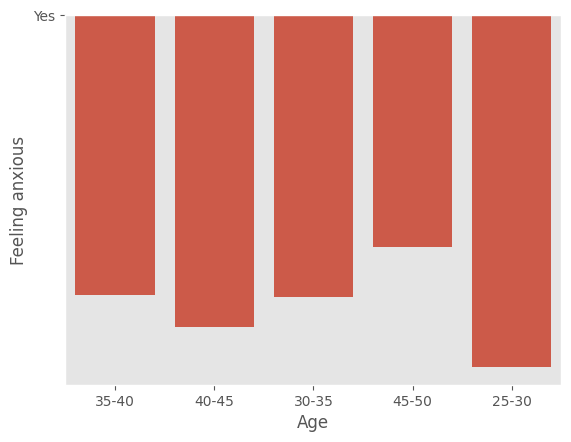

In [57]:
# Age vs Feeling Anxious
Age_plot = sns.barplot(x='Age', y='Feeling anxious', data=df_copy, ci=None)



### The most common age in the data is 40-45, but the highest representation of Yes correlates mostly with 25-30 year olds

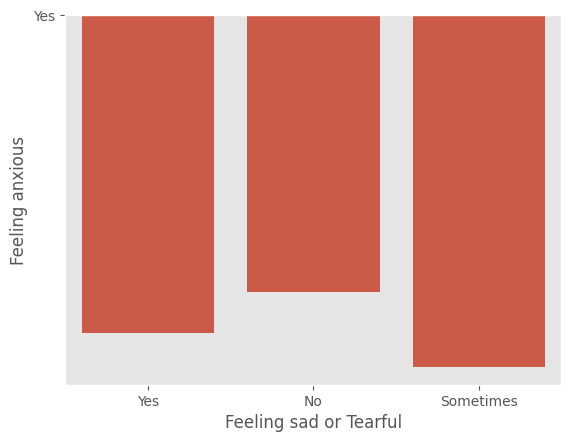

In [62]:
#Feeling sad or Tearful vs Feeling Anxious
Feeling_sad_plot = sns.barplot(x='Feeling sad or Tearful', y='Feeling anxious', data=df_copy, ci=None)


No direct correlation of Feeling sad or Tearful wtih the target as 'sometimes' seem to be the highest.

In [60]:
#Trouble sleeping at night  vs Feeling anxious



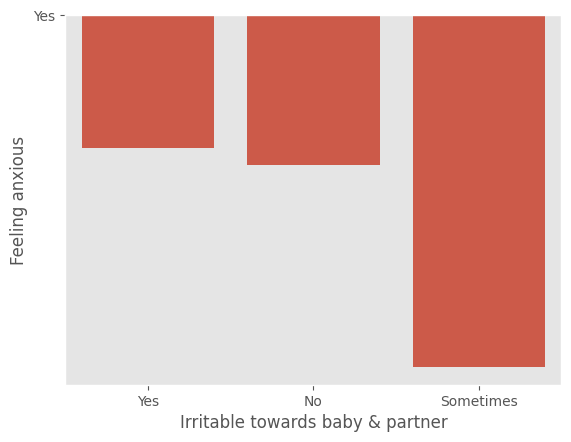

In [61]:
#Irritable towards baby & partner vs Feeling anxioud
Irritable_plot = sns.barplot(x='Irritable towards baby & partner', y='Feeling anxious', data=df_copy, ci=None)

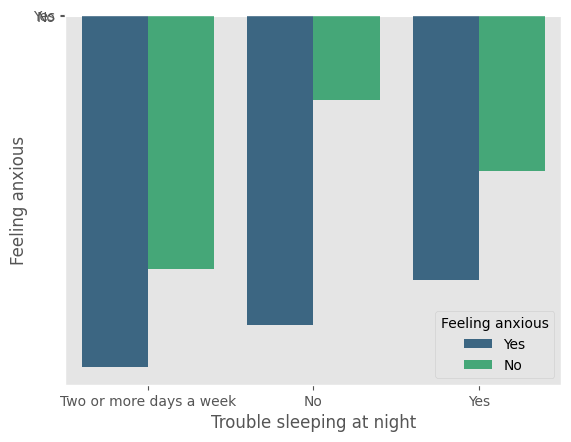

In [64]:
#Trouble sleeping at night vs Feeling anxious
Trouble_sleeping_plot = sns.barplot(x='Trouble sleeping at night', y='Feeling anxious', data=df_copy, ci=None)
sns.countplot(x='Trouble sleeping at night', hue='Feeling anxious', data=df_copy, palette='viridis')
plt.show()

There seems to be some correlation of sleep and feeling anxious

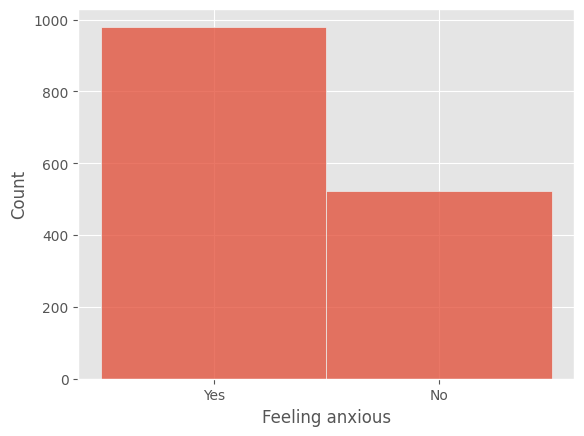

In [32]:
sns.histplot(data=df, x='Feeling sad or Tearful')
plt.show()

The above plot shows that the outcome is not normally distributed and there is over-repesentation of the 'Yes'. Some undersampling or oversampling will be needed.


In [44]:
x = df.loc[:, df.columns != 'Feeling anxious']
y = df.loc[:, 'Feeling anxious']
print(x.shape, y.shape)

(1503, 9) (1503,)


In [7]:
#let's convert all the categorical data into numerical but define clearly what they stand for
# Displaying unique values in each column
for column in df.columns:
    unique_values = df[column].unique()
    print(f'Unique values in {column}: {unique_values}')

Unique values in Age: ['35-40' '40-45' '30-35' '45-50' '25-30']
Unique values in Feeling sad or Tearful: ['Yes' 'No' 'Sometimes']
Unique values in Irritable towards baby & partner: ['Yes' 'No' 'Sometimes' nan]
Unique values in Trouble sleeping at night: ['Two or more days a week' 'No' 'Yes']
Unique values in Problems concentrating or making decision: ['Yes' 'No' 'Often' nan]
Unique values in Overeating or loss of appetite: ['Yes' 'No' 'Not at all']
Unique values in Feeling of guilt: ['No' 'Yes' 'Maybe' nan]
Unique values in Problems of bonding with baby: ['Yes' 'Sometimes' 'No']
Unique values in Suicide attempt: ['Yes' 'No' 'Not interested to say']
Unique values in Feeling anxious: ['Yes' 'No']


Let's assign values to all unique values:
Age: 25-30=0, 30-35=1, 35-40=2, 40-45=3, 45-50=4
Feeling sad or tearful: Yes=1, no=0, sometimes=3
Irritable: Yes=1, no=0, sometimes=3
Trouble sleepinh: Yes=1, no=0, two or more days=3
Problems concentrating: Yes=1, No=2, Often=3
Overeating or loss of appetite: Yes=1, No=0, not at all=3
Feeling of guilt: yes=1, no=2, maybe=3
Problems of bonding with baby: Yes=1, n0=0, sometimes=3
Suicide attempt:Yes=1, no=0, not interested to say=3
Feeling anxious: yes=1, no=0


In [8]:
x_replaced=x.copy()
x_replaced = {'Age': ['25-30', '30-35', '35-40', '40-45', '45-50'],
        'Feeling sad or Tearful': ['Yes', 'No', 'Sometimes'],
        'Irritable towards baby & partner': ['Yes', 'No', 'Sometimes', 'NaN'],
        'Trouble sleeping at night': ['Yes', 'No', 'Two or more days a week'],
        'Problems concentrating or making decision': ['Yes', 'No', 'Often', 'NaN'],
        'Overeating or loss of appetite': ['Yes', 'No', 'Not at all'],
        'Feeling of guilt': ['Yes', 'No', 'Maybe', 'NaN'],
        'Problems of bonding with baby': ['Yes', 'No', 'Sometimes'],
        'Suicide attempt': ['Yes', 'No', 'Not intersted to say']}

mapping = {'25-30': 0, '30-35': 1, '35-40': 2, '40-45': 3, '45-50': 4}



